In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

leads = pd.read_csv("../data/processed/cleaned_marketing_leads.csv")
deals = pd.read_csv("../data/processed/cleaned_closed_deals.csv")

leads['first_contact_date'] = pd.to_datetime(leads['first_contact_date'])
deals['won_date'] = pd.to_datetime(deals['won_date'])

print("Leads:", leads.shape)
print("Deals:", deals.shape)

Leads: (8000, 4)
Deals: (842, 14)


In [2]:
"data/processed/cleaned_marketing_leads.csv"
"data/processed/cleaned_closed_deals.csv"

'data/processed/cleaned_closed_deals.csv'

In [4]:
funnel = leads.merge(
    deals[['mql_id', 'won_date', 'business_segment', 'lead_type',
           'declared_monthly_revenue']],
    on='mql_id',
    how='left',
    indicator=True
)

funnel['converted'] = (funnel['_merge'] == 'both').astype(int)

total_leads = len(funnel)
converted_leads = funnel['converted'].sum()
not_converted = total_leads - converted_leads

conversion_rate = (converted_leads / total_leads) * 100

print("Total Qualified Leads:", total_leads)
print("Closed Deals:", converted_leads)
print("Not Converted:", not_converted)
print("Conversion Rate:", round(conversion_rate, 2), "%")

Total Qualified Leads: 8000
Closed Deals: 842
Not Converted: 7158
Conversion Rate: 10.52 %


In [5]:
origin_analysis = funnel.groupby('origin').agg(
    total_leads=('mql_id', 'count'),
    converted_leads=('converted', 'sum')
).reset_index()

origin_analysis['conversion_rate'] = (
    origin_analysis['converted_leads'] /
    origin_analysis['total_leads'] * 100
)

display(origin_analysis.sort_values('conversion_rate', ascending=False))

,origin,total_leads,converted_leads,conversion_rate
9,unknown,1099,179,16.287534
6,paid_search,1586,195,12.295082
3,organic_search,2296,271,11.803136
0,direct_traffic,499,56,11.222445
7,referral,284,24,8.450704
8,social,1350,75,5.555556
1,display,118,6,5.084746
5,other_publicities,65,3,4.615385
2,email,493,15,3.042596
4,other,150,4,2.666667


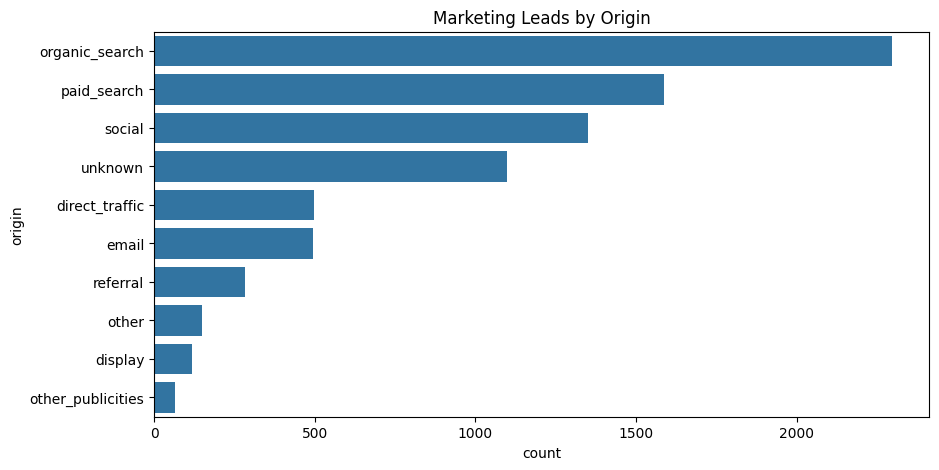

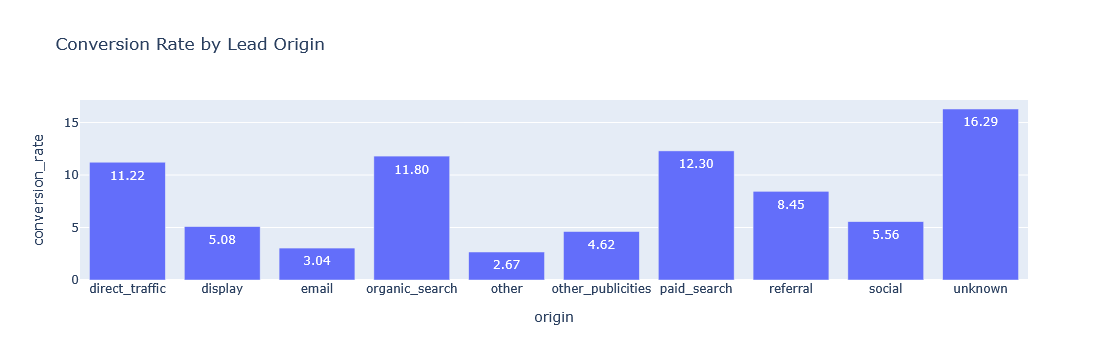

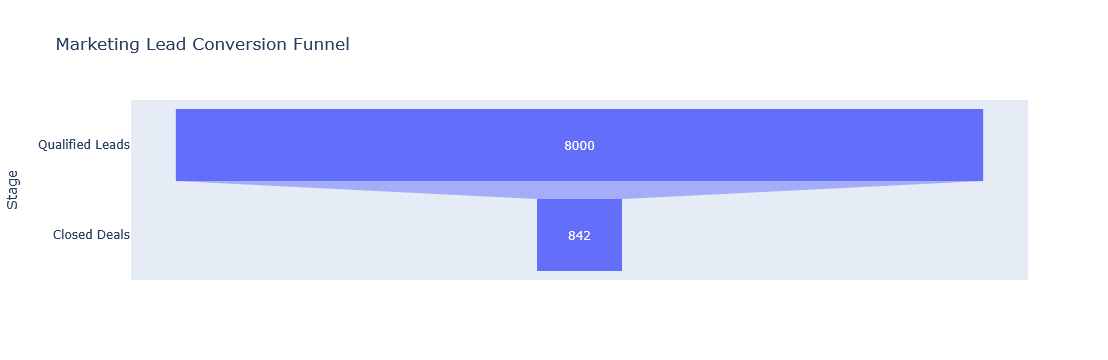

In [6]:
# Lead Origin Distribution
plt.figure(figsize=(10, 5))
sns.countplot(data=leads, y='origin',
              order=leads['origin'].value_counts().index)
plt.title("Marketing Leads by Origin")
plt.show()

# Conversion Rate by Origin
fig = px.bar(
    origin_analysis,
    x='origin',
    y='conversion_rate',
    title='Conversion Rate by Lead Origin',
    text_auto='.2f'
)
fig.show()

# Marketing Funnel
fig = px.funnel(
    pd.DataFrame({
        'Stage': ['Qualified Leads', 'Closed Deals'],
        'Count': [total_leads, converted_leads]
    }),
    x='Count',
    y='Stage',
    title='Marketing Lead Conversion Funnel'
)
fig.show()

In [7]:
# Lead source performance
source_analysis = funnel.groupby('origin').agg(
    total_leads=('mql_id', 'count'),
    closed_deals=('converted', 'sum')
).reset_index()

source_analysis['conversion_rate'] = (
    source_analysis['closed_deals'] /
    source_analysis['total_leads'] * 100
)

source_analysis['conversion_rate'] = source_analysis['conversion_rate'].round(2)

display(source_analysis.sort_values('closed_deals', ascending=False))

,origin,total_leads,closed_deals,conversion_rate
3,organic_search,2296,271,11.80
6,paid_search,1586,195,12.30
9,unknown,1099,179,16.29
8,social,1350,75,5.56
0,direct_traffic,499,56,11.22
7,referral,284,24,8.45
2,email,493,15,3.04
1,display,118,6,5.08
4,other,150,4,2.67
5,other_publicities,65,3,4.62


,month,total_leads,closed_deals
0,2017-06,4,0.0
1,2017-07,239,0.0
2,2017-08,386,0.0
3,2017-09,312,0.0
4,2017-10,416,0.0
5,2017-11,445,0.0
6,2017-12,200,3.0
7,2018-01,1141,73.0
8,2018-02,1028,113.0
9,2018-03,1174,147.0


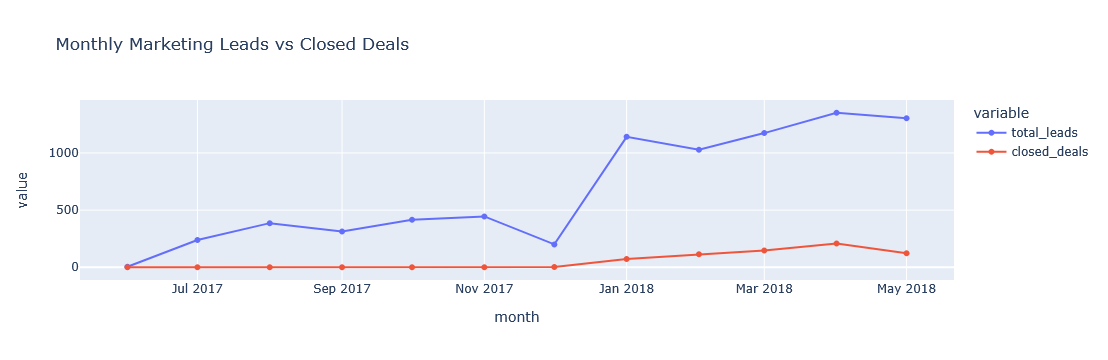

In [8]:
# Monthly lead count
leads['month'] = leads['first_contact_date'].dt.to_period('M').astype(str)

monthly_leads = leads.groupby('month').size().reset_index(name='total_leads')

# Monthly closed deals
deals['month'] = deals['won_date'].dt.to_period('M').astype(str)

monthly_deals = deals.groupby('month').size().reset_index(name='closed_deals')

# Merge monthly data
monthly_analysis = monthly_leads.merge(
    monthly_deals, on='month', how='left'
).fillna(0)

display(monthly_analysis)

# Visualization
fig = px.line(
    monthly_analysis,
    x='month',
    y=['total_leads', 'closed_deals'],
    markers=True,
    title='Monthly Marketing Leads vs Closed Deals'
)
fig.show()

In [9]:
# Calculate time taken to close a deal
funnel['conversion_days'] = (
    funnel['won_date'] - pd.to_datetime(funnel['first_contact_date'])
).dt.days

print("Average Conversion Time:",
      round(funnel['conversion_days'].mean(), 2), "days")

print("Median Conversion Time:",
      funnel['conversion_days'].median(), "days")

display(funnel[funnel['converted'] == 1]['conversion_days'].describe())

Average Conversion Time: 48.44 days
Median Conversion Time: 14.0 days


count    842.000000
mean      48.440618
std       75.328117
min       -2.000000
25%        5.000000
50%       14.000000
75%       54.750000
max      427.000000
Name: conversion_days, dtype: float64

In [10]:
import os

# Create reports folder if not present
os.makedirs("../reports", exist_ok=True)

# Export analysis reports
origin_analysis.to_csv("../reports/lead_origin_analysis.csv", index=False)

source_analysis.to_csv("../reports/marketing_channel_performance.csv", index=False)

monthly_analysis.to_csv("../reports/monthly_lead_conversion.csv", index=False)

# Conversion time report
conversion_time = funnel[funnel['converted'] == 1][
    ['mql_id', 'first_contact_date', 'won_date', 'conversion_days']
]

conversion_time.to_csv("../reports/conversion_time_analysis.csv", index=False)

# Export merged funnel data
funnel.to_csv("../reports/marketing_funnel_analysis.csv", index=False)

print("All EDA reports exported successfully!")
print("Total reports created: 5")

All EDA reports exported successfully!
Total reports created: 5


In [11]:
# Business Segment Analysis
segment_analysis = deals['business_segment'].value_counts().reset_index()
segment_analysis.columns = ['business_segment', 'closed_deals']

print("CLOSED DEALS BY BUSINESS SEGMENT")
display(segment_analysis)

# Lead Type Analysis
lead_type_analysis = deals['lead_type'].value_counts().reset_index()
lead_type_analysis.columns = ['lead_type', 'closed_deals']

print("\nCLOSED DEALS BY LEAD TYPE")
display(lead_type_analysis)

# Revenue Analysis
print("\nDECLARED MONTHLY REVENUE SUMMARY")
display(deals['declared_monthly_revenue'].describe())

CLOSED DEALS BY BUSINESS SEGMENT


,business_segment,closed_deals
0,home_decor,105
1,health_beauty,93
2,car_accessories,77
3,household_utilities,71
4,construction_tools_house_garden,69
5,audio_video_electronics,64
6,computers,34
7,pet,30
8,food_supplement,28
9,food_drink,26



CLOSED DEALS BY LEAD TYPE


,lead_type,closed_deals
0,online_medium,332
1,online_big,126
2,industry,123
3,offline,104
4,online_small,77
5,online_beginner,57
6,online_top,14
7,other,3



DECLARED MONTHLY REVENUE SUMMARY


count    8.420000e+02
mean     7.337768e+04
std      1.744799e+06
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      5.000000e+07
Name: declared_monthly_revenue, dtype: float64

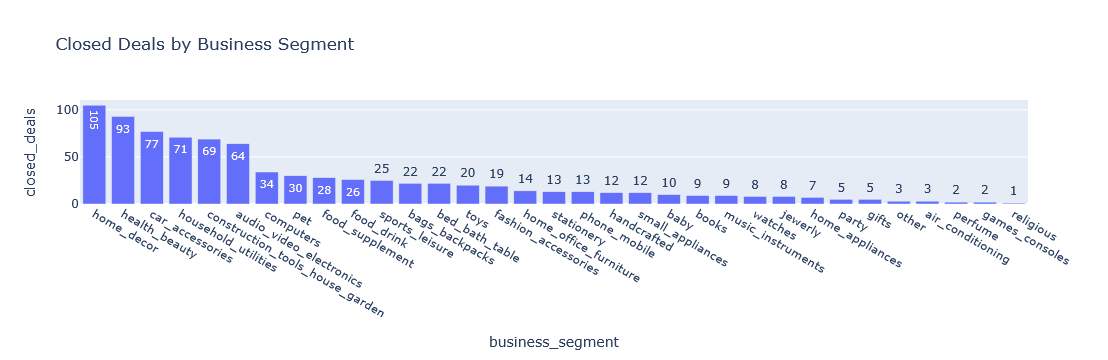

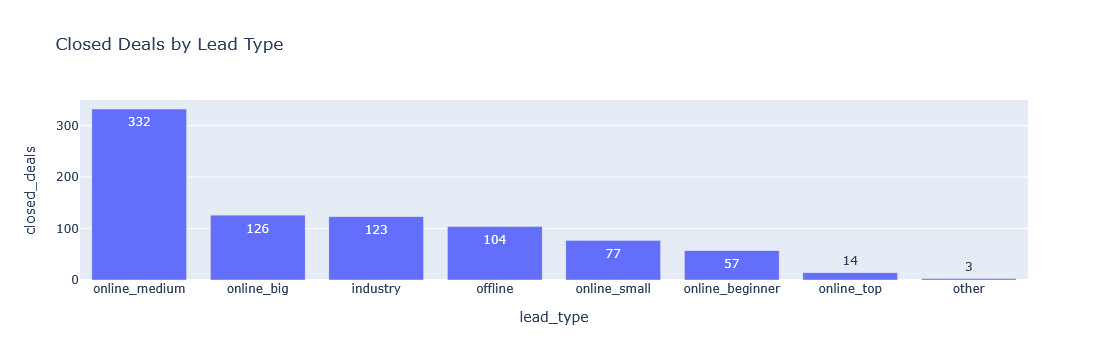

In [12]:
fig = px.bar(
    segment_analysis,
    x='business_segment',
    y='closed_deals',
    title='Closed Deals by Business Segment',
    text_auto=True
)
fig.show()

fig = px.bar(
    lead_type_analysis,
    x='lead_type',
    y='closed_deals',
    title='Closed Deals by Lead Type',
    text_auto=True
)
fig.show()

In [13]:
# Export business segment and lead type analysis
segment_analysis.to_csv(
    "../reports/business_segment_analysis.csv", index=False
)

lead_type_analysis.to_csv(
    "../reports/lead_type_analysis.csv", index=False
)

# Revenue summary
revenue_summary = deals['declared_monthly_revenue'].describe().reset_index()
revenue_summary.columns = ['metric', 'value']

revenue_summary.to_csv(
    "../reports/revenue_summary.csv", index=False
)

print("Business analysis reports exported successfully!")

Business analysis reports exported successfully!


In [14]:
import os

print("Reports folder:")
for file in os.listdir("../reports"):
    print(file)

Reports folder:
business_segment_analysis.csv
conversion_time_analysis.csv
lead_origin_analysis.csv
lead_type_analysis.csv
marketing_channel_performance.csv
marketing_funnel_analysis.csv
monthly_lead_conversion.csv
revenue_summary.csv
